2026-02-20 19:30:31.452691: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1771615831.694936      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1771615831.755812      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1771615832.309282      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771615832.309328      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1771615832.309331      55 computation_placer.cc:177] computation placer alr

All imports successful.
TensorFlow version: 2.19.0
Loading subject 1...


/tmp/ipykernel_55/944965833.py:77: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  start = int(a_trial[trial])
/tmp/ipykernel_55/944965833.py:81: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  class_return[NO_valid_trial] = int(a_y[trial])


X_train_raw: (288, 22, 1000)   y_train_raw: (288,)
X_test_raw : (288, 22, 1000)   y_test_raw : (288,)
CutCat augmentation (factor=25)...
  Before: 288 trials  →  After: 7488 trials

After transpose (channels-last):
X_train_cl: (7488, 1000, 22)
X_test_cl : (288, 1000, 22)
Train   : (6739, 1000, 22)  labels: (6739,)
Val     : (749, 1000, 22)  labels: (749,)
Test    : (288, 1000, 22)  labels: (288,)
Applying band filters ...
Done.


I0000 00:00:1771615900.166729      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1771615900.172804      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


...

106/106 - 2s - 19ms/step - accuracy: 0.9941 - loss: 0.0460 - val_accuracy: 0.9987 - val_loss: 0.0303
Epoch 107/1320

Epoch 107: val_loss did not improve from 0.03029
106/106 - 2s - 18ms/step - accuracy: 0.9963 - loss: 0.0449 - val_accuracy: 0.9973 - val_loss: 0.0361
Epoch 108/1320

Epoch 108: val_loss did not improve from 0.03029
106/106 - 2s - 18ms/step - accuracy: 0.9963 - loss: 0.0451 - val_accuracy: 1.0000 - val_loss: 0.0350
Epoch 109/1320

Epoch 109: val_loss did not improve from 0.03029
106/106 - 2s - 18ms/step - accuracy: 0.9953 - loss: 0.0451 - val_accuracy: 1.0000 - val_loss: 0.0317
Epoch 110/1320

Epoch 110: val_loss did not improve from 0.03029
106/106 - 2s - 18ms/step - accuracy: 0.9954 - loss: 0.0434 - val_accuracy: 0.9987 - val_loss: 0.0365
Epoch 111/1320

Epoch 111: val_loss improved from 0.03029 to 0.02696, saving model to STSPecResult_A2_2S1/best_model.h5


106/106 - 2s - 19ms/step - accuracy: 0.9958 - loss: 0.0424 - val_accuracy: 1.0000 - val_loss: 0.0270
Epoch 112/1320

Epoch 112: val_loss improved from 0.02696 to 0.02665, saving model to STSPecResult_A2_2S1/best_model.h5


106/106 - 2s - 19ms/step - accuracy: 0.9950 - loss: 0.0425 - val_accuracy: 1.0000 - val_loss: 0.0267
Epoch 113/1320

Epoch 113: val_loss did not improve from 0.02665
106/106 - 2s - 18ms/step - accuracy: 0.9958 - loss: 0.0420 - val_accuracy: 1.0000 - val_loss: 0.0305
Epoch 114/1320

Epoch 114: val_loss did not improve from 0.02665
106/106 - 2s - 18ms/step - accuracy: 0.9973 - loss: 0.0382 - val_accuracy: 0.9973 - val_loss: 0.0328
Epoch 115/1320

Epoch 115: val_loss did not improve from 0.02665
106/106 - 2s - 18ms/step - accuracy: 0.9954 - loss: 0.0425 - val_accuracy: 0.9987 - val_loss: 0.0326
Epoch 116/1320

Epoch 116: val_loss did not improve from 0.02665
106/106 - 2s - 19ms/step - accuracy: 0.9947 - loss: 0.0415 - val_accuracy: 1.0000 - val_loss: 0.0278
Epoch 117/1320

Epoch 117: val_loss did not improve from 0.02665
106/106 - 2s - 18ms/step - accuracy: 0.9966 - loss: 0.0391 - val_accuracy: 0.9880 - val_loss: 0.0574
Epoch 118/1320

Epoch 118: val_loss did not improve from 0.02665
106/

106/106 - 2s - 19ms/step - accuracy: 0.9957 - loss: 0.0388 - val_accuracy: 1.0000 - val_loss: 0.0260
Epoch 120/1320

Epoch 120: val_loss=0.0250 ≤ 0.025, stopping.

Epoch 120: val_loss improved from 0.02602 to 0.02497, saving model to STSPecResult_A2_2S1/best_model.h5


106/106 - 2s - 19ms/step - accuracy: 0.9964 - loss: 0.0374 - val_accuracy: 1.0000 - val_loss: 0.0250

Training finished in 4m 21.8s
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step

  Train Metrics
  Accuracy : 1.0000
  Precision: 1.0000
  Recall   : 1.0000
  F1-score : 1.0000
  Kappa    : 1.0000
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step

  Validation Metrics
  Accuracy : 1.0000
  Precision: 1.0000
  Recall   : 1.0000
  F1-score : 1.0000
  Kappa    : 1.0000
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 

  Test Metrics
  Accuracy : 0.8229
  Precision: 0.8299
  Recall   : 0.8229
  F1-score : 0.8232
  Kappa    : 0.7639
Confusion matrices saved.


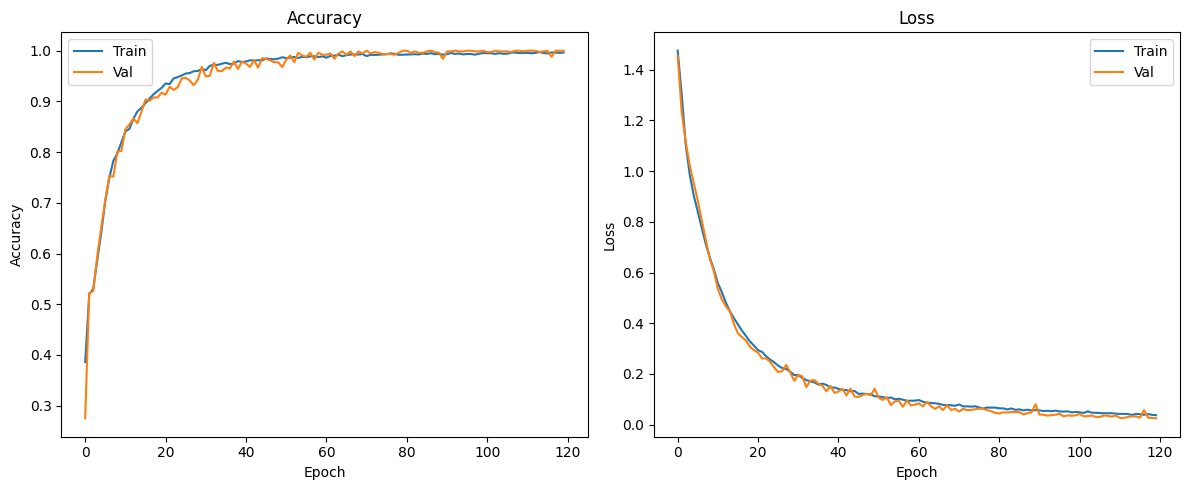

Learning curves saved.
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


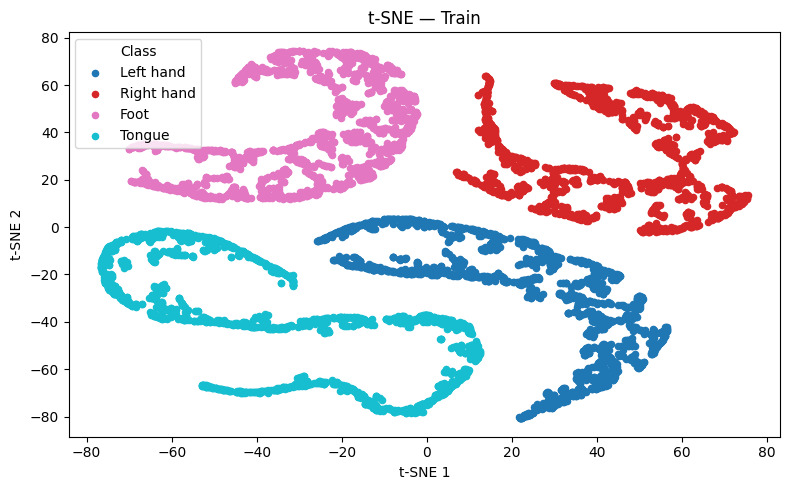

t-SNE (Train) saved.
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


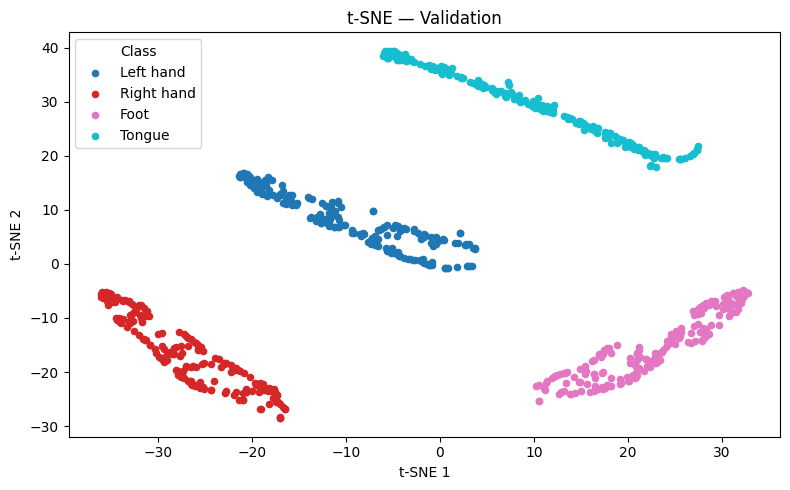

t-SNE (Validation) saved.
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


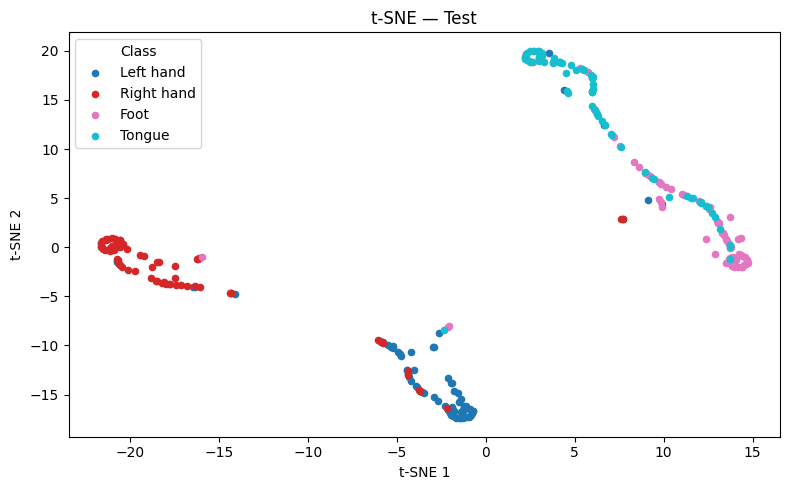

t-SNE (Test) saved.
Training history saved.

All results written to: STSPecResult_A2_2S1


In [1]:
# ============================================================
# CELL 1 — Imports
# ============================================================
import os
import time

import numpy as np
import pandas as pd
import scipy.io as sio

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.callbacks import ModelCheckpoint, Callback
from tensorflow.keras import backend as K, regularizers
from tensorflow.keras.layers import (
    Input, Dense, Activation, Conv1D, Conv2D, AveragePooling2D,
    SeparableConv2D, BatchNormalization, Dropout, Add, Lambda,
    DepthwiseConv2D, Permute, Reshape, GlobalAveragePooling1D,
    GlobalMaxPooling1D, MaxPooling1D, Multiply, Concatenate
)
from tensorflow.keras.constraints import max_norm
from tensorflow import Variable

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler

from scipy.signal import butter, filtfilt
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

print("All imports successful.")
print(f"TensorFlow version: {tf.__version__}")


# ============================================================
# CELL 2 — Data Loading Functions
# ============================================================
def load_BCI2a_data(data_path, subject, training, all_trials=True):
    """Load BCI Competition IV Dataset 2a for a single subject."""
    n_channels   = 22
    n_tests      = 6 * 48
    window_length = 7 * 250          # 7 seconds @ 250 Hz

    fs = 250
    t1 = int(2 * fs)                 # crop 2-6 s (motor imagery window)
    t2 = int(6 * fs)

    class_return = np.zeros(n_tests)
    data_return  = np.zeros((n_tests, n_channels, window_length))

    NO_valid_trial = 0
    suffix = "T" if training else "E"
    file_path = os.path.join(data_path, f"A0{subject}{suffix}.mat")

    a      = sio.loadmat(file_path)
    a_data = a['data']

    for ii in range(a_data.size):
        a_data1    = a_data[0, ii]
        a_data3    = a_data1[0, 0]
        a_X        = a_data3[0]
        a_trial    = a_data3[1]
        a_y        = a_data3[2]
        a_artifacts = a_data3[5]

        for trial in range(a_trial.size):
            if a_artifacts[trial] != 0 and not all_trials:
                continue
            start = int(a_trial[trial])
            data_return[NO_valid_trial, :, :] = np.transpose(
                a_X[start : start + window_length, :22]
            )
            class_return[NO_valid_trial] = int(a_y[trial])
            NO_valid_trial += 1

    data_return  = data_return[:NO_valid_trial, :, t1:t2]   # (N, 22, 1000)
    class_return = (class_return[:NO_valid_trial] - 1).astype(int)
    return data_return, class_return


def get_data(path, subject):
    """Return train/test arrays for one subject, shape (N, 22, 1000)."""
    X_train, y_train = load_BCI2a_data(path, subject, training=True)
    X_test,  y_test  = load_BCI2a_data(path, subject, training=False)
    return X_train, y_train, X_test, y_test


# ============================================================
# CELL 3 — Load Raw Data
# ============================================================
data_path = r"/kaggle/input/datasets/uddeshaypersonal/bci-competition-iv-2a-dataset"
subjects  = [1]

all_X_train, all_y_train = [], []
all_X_test,  all_y_test  = [], []

for subject in subjects:
    print(f"Loading subject {subject}...")
    X_tr, y_tr, X_te, y_te = get_data(data_path, subject)
    all_X_train.append(X_tr);  all_y_train.append(y_tr)
    all_X_test.append(X_te);   all_y_test.append(y_te)

# Shape: (N, 22, 1000)  — channels-last conversion happens AFTER augmentation
X_train_raw = np.concatenate(all_X_train, axis=0)
y_train_raw = np.concatenate(all_y_train, axis=0)
X_test_raw  = np.concatenate(all_X_test,  axis=0)
y_test_raw  = np.concatenate(all_y_test,  axis=0)

print("X_train_raw:", X_train_raw.shape, "  y_train_raw:", y_train_raw.shape)
print("X_test_raw :", X_test_raw.shape,  "  y_test_raw :", y_test_raw.shape)


# ============================================================
# CELL 4 — CutCat Augmentation  (applied ONLY to training data)
# ============================================================
def augment_with_cutcat(X_data, y_data, expansion_factor=15):
    """
    CutCat augmentation: splice 4 quarter-segments from two same-class trials.
    Pattern: [A_seg1, B_seg2, A_seg3, B_seg4]

    Args:
        X_data          : (N, channels, time)
        y_data          : (N,)
        expansion_factor: number of synthetic trials per original trial
    Returns:
        X_final, y_final: original + synthetic concatenated
    """
    print(f"CutCat augmentation (factor={expansion_factor})...")
    n_trials, n_channels, n_time = X_data.shape
    quarter_len = n_time // 4

    # Group indices by class
    class_groups = {c: np.where(y_data == c)[0] for c in np.unique(y_data)}

    X_aug, y_aug = [], []
    for i in range(n_trials):
        label   = y_data[i]
        trial_a = X_data[i]
        for _ in range(expansion_factor):
            idx_b   = np.random.choice(class_groups[label])
            trial_b = X_data[idx_b]

            new_trial = np.concatenate([
                trial_a[:, 0             : quarter_len],
                trial_b[:, quarter_len   : 2*quarter_len],
                trial_a[:, 2*quarter_len : 3*quarter_len],
                trial_b[:, 3*quarter_len :              ],
            ], axis=1)

            X_aug.append(new_trial)
            y_aug.append(label)

    X_aug = np.array(X_aug, dtype=np.float32)
    y_aug = np.array(y_aug, dtype=int)

    X_final = np.concatenate([X_data.astype(np.float32), X_aug], axis=0)
    y_final = np.concatenate([y_data, y_aug], axis=0)
    print(f"  Before: {X_data.shape[0]} trials  →  After: {X_final.shape[0]} trials")
    return X_final, y_final


# ✅ FIX: augment ONLY the training split; test data is never touched
EXPANSION_FACTOR = 25
X_train_aug, y_train_aug = augment_with_cutcat(X_train_raw, y_train_raw, expansion_factor=EXPANSION_FACTOR)
X_test_aug  = X_test_raw           # kept as-is (no augmentation on test)
y_test_aug  = y_test_raw

# Convert from (N, 22, 1000) → (N, 1000, 22)  [channels-last for Conv1D]
X_train_cl = X_train_aug.transpose(0, 2, 1)   # (N, 1000, 22)
X_test_cl  = X_test_aug.transpose(0, 2, 1)

print("\nAfter transpose (channels-last):")
print("X_train_cl:", X_train_cl.shape)
print("X_test_cl :", X_test_cl.shape)


# ============================================================
# CELL 5 — Train / Validation / Test Split
# ============================================================
# ✅ FIX: validation carved out of the augmented TRAIN set only;
#         test set = original BCI test data, never mixed.
VAL_FRACTION  = 0.1    # 10% of augmented train → validation
NUM_CLASSES   = 4
BATCH_SIZE    = 64
EPOCHS        = 1320
RANDOM_STATE  = 42

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_cl, y_train_aug,
    test_size   = VAL_FRACTION,
    stratify    = y_train_aug,
    random_state = RANDOM_STATE
)

print(f"Train   : {X_tr.shape}  labels: {y_tr.shape}")
print(f"Val     : {X_val.shape}  labels: {y_val.shape}")
print(f"Test    : {X_test_cl.shape}  labels: {y_test_aug.shape}")

# One-hot encode
y_tr_oh  = to_categorical(y_tr,       NUM_CLASSES)
y_val_oh = to_categorical(y_val,      NUM_CLASSES)
# (test labels stay integer for sklearn metrics)


# ============================================================
# CELL 6 — Band-Pass Filtering  (theta / alpha / beta)
# ============================================================
def apply_band_filters(X_data, fs=250, order=4):
    """
    Band-pass filter EEG data.
    Input shape : (N, time, channels)
    Returns     : tuple of filtered arrays (delta, theta, alpha, beta, gamma)
    """
    # Remove DC offset
    X_data = X_data - np.mean(X_data, axis=1, keepdims=True)

    bands = {
        'delta': (0.5,  4),
        'theta': (4,    8),
        'alpha': (8,   13),
        'beta' : (13,  30),
        'gamma': (30,  80),   # kept below 100 to avoid Nyquist issues at 250 Hz
    }

    n_samples, n_time, n_channels = X_data.shape
    # Reshape to (samples*channels, time) for filtering along time axis
    X_reshaped = X_data.transpose(0, 2, 1).reshape(-1, n_time)

    band_data = {}
    for name, (low, high) in bands.items():
        nyq = 0.5 * fs
        Wn  = [low / nyq, high / nyq]
        b, a = butter(order, Wn, btype='bandpass')
        padlen   = min(150, n_time // 2)
        filtered = filtfilt(b, a, X_reshaped, axis=1, padlen=padlen)
        # Reshape back: (N, time, channels)
        band_data[name] = filtered.reshape(n_samples, n_channels, n_time).transpose(0, 2, 1)

    return (band_data['delta'], band_data['theta'],
            band_data['alpha'], band_data['beta'], band_data['gamma'])


print("Applying band filters ...")
_, X_tr_theta,  X_tr_alpha,  X_tr_beta,  _ = apply_band_filters(X_tr)
_, X_val_theta, X_val_alpha, X_val_beta, _ = apply_band_filters(X_val)
_, X_te_theta,  X_te_alpha,  X_te_beta,  _ = apply_band_filters(X_test_cl)
print("Done.")


# ============================================================
# CELL 7 — Attention Modules
# ============================================================
class Channel_attention(Model):
    def __init__(self, num_ch):
        super().__init__(name='channel_attention')
        self.conv1   = Conv2D(8, (1,1), kernel_constraint=max_norm(2., axis=(0,1,2)))
        self.conv2   = Conv2D(8, (1,1), kernel_constraint=max_norm(2., axis=(0,1,2)))
        self.reshape = Reshape((num_ch, -1))
        self.gamma   = Variable(initial_value=0., dtype='float32', trainable=True)

    def call(self, x):
        proj_query = self.reshape(self.conv1(x))
        proj_key   = self.reshape(self.conv2(x))
        energy     = tf.matmul(proj_query, proj_key, transpose_b=True)
        max_H      = tf.reduce_max(energy, axis=2, keepdims=True)
        min_H      = tf.reduce_min(energy, axis=2, keepdims=True)
        energy     = (energy - min_H) / (max_H - min_H + 1e-8)
        attention  = tf.nn.softmax(energy)
        out = (self.gamma *
               tf.expand_dims(tf.matmul(attention, tf.squeeze(x, axis=-1), transpose_a=True), axis=3)
               + x)
        return out


class Time_attention(Model):
    def __init__(self, num_t):
        super().__init__(name='time_attention')
        self.conv1   = Conv2D(8, (1,1), kernel_constraint=max_norm(2., axis=(0,1,2)))
        self.conv2   = Conv2D(8, (1,1), kernel_constraint=max_norm(2., axis=(0,1,2)))
        self.reshape = Reshape((num_t, -1))
        self.permute = Permute((2, 1, 3))
        self.gamma   = Variable(initial_value=0., dtype='float32', trainable=True)

    def call(self, x):
        proj_query = self.reshape(self.permute(self.conv1(x)))
        proj_key   = self.reshape(self.permute(self.conv2(x)))
        energy     = tf.matmul(proj_query, proj_key, transpose_b=True)
        max_H      = tf.reduce_max(energy, axis=2, keepdims=True)
        min_H      = tf.reduce_min(energy, axis=2, keepdims=True)
        energy     = (energy - min_H) / (max_H - min_H + 1e-8)
        attention  = tf.nn.softmax(energy)
        out = (self.gamma *
               tf.expand_dims(tf.matmul(tf.squeeze(x, axis=-1), attention, transpose_b=True), axis=3)
               + x)
        return out


# ============================================================
# CELL 8 — CBAM (1-D) Helper Functions
# ============================================================
def channel_attention_1d(input_feature, ratio=8):
    channel = input_feature.shape[-1]
    shared1 = Dense(channel // ratio, activation='relu',
                    kernel_initializer='he_normal', use_bias=True)
    shared2 = Dense(channel, kernel_initializer='he_normal', use_bias=True)

    avg = GlobalAveragePooling1D()(input_feature)
    avg = Reshape((1, channel))(avg)
    avg = shared2(shared1(avg))

    mx  = GlobalMaxPooling1D()(input_feature)
    mx  = Reshape((1, channel))(mx)
    mx  = shared2(shared1(mx))

    feat = Activation('sigmoid')(Add()([avg, mx]))
    return Multiply()([input_feature, feat])


def spatial_attention_1d(input_feature):
    avg_pool = Lambda(lambda x: K.mean(x, axis=2, keepdims=True))(input_feature)
    max_pool = Lambda(lambda x: K.max(x,  axis=2, keepdims=True))(input_feature)
    concat   = Concatenate(axis=2)([avg_pool, max_pool])
    feat     = Conv1D(1, 7, padding='same', activation='sigmoid',
                      kernel_initializer='he_normal', use_bias=False)(concat)
    return Multiply()([input_feature, feat])


def cbam_block_1d(input_feature, residual=False):
    out = channel_attention_1d(input_feature)
    out = spatial_attention_1d(out)
    if residual:
        out = Add()([input_feature, out])
    return out


# ============================================================
# CELL 9 — Build Model
# ============================================================
temporal_dim = X_tr.shape[1]     # 1000
num_ch       = X_tr.shape[2]     # 22

input_main  = Input(shape=(temporal_dim, num_ch), name="input_main")
input_theta = Input(shape=(temporal_dim, num_ch), name="input_theta")
input_alpha = Input(shape=(temporal_dim, num_ch), name="input_alpha")
input_beta  = Input(shape=(temporal_dim, num_ch), name="input_beta")

# Concatenate broadband + band-specific inputs along channel axis
fused = Concatenate(axis=-1)([input_main, input_theta, input_alpha, input_beta])  # (N, 1000, 88)

x = Conv1D(32, 5, activation='relu', padding='same')(fused)
x = MaxPooling1D(2)(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)

x = Conv1D(64, 3, activation='relu', padding='same')(x)
x = BatchNormalization()(x)

# CBAM attention over 1-D feature maps
x = cbam_block_1d(x)

x = GlobalAveragePooling1D()(x)
x = Dropout(0.3)(x)

x = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.002))(x)
x = Dense(NUM_CLASSES)(x)
x = Activation('softmax')(x)

model = Model(
    inputs  = [input_main, input_theta, input_alpha, input_beta],
    outputs = x,
    name    = "BCI_Multiband_CBAM"
)
model.summary()


# ============================================================
# CELL 10 — Compile & Callbacks
# ============================================================
model.compile(
    loss      = 'categorical_crossentropy',
    optimizer = Adam(learning_rate=1e-4),
    metrics   = ['accuracy']          # per-batch precision/recall are misleading; use sklearn post-hoc
)

results_dir = "STSPecResult_A2_2S1"
os.makedirs(results_dir, exist_ok=True)


class ThresholdStopping(Callback):
    """Stop training when monitored metric reaches a threshold."""
    def __init__(self, monitor='val_loss', threshold=0.025):
        super().__init__()
        self.monitor   = monitor
        self.threshold = threshold

    def on_epoch_end(self, epoch, logs=None):
        val = logs.get(self.monitor)
        if val is not None and val <= self.threshold:
            print(f"\nEpoch {epoch+1}: {self.monitor}={val:.4f} ≤ {self.threshold}, stopping.")
            self.model.stop_training = True


callbacks = [
    ThresholdStopping(monitor='val_loss', threshold=0.025),
    ModelCheckpoint(
        filepath      = os.path.join(results_dir, 'best_model.h5'),
        monitor       = 'val_loss',
        save_best_only = True,
        mode          = 'min',
        verbose       = 1
    )
]


# ============================================================
# CELL 11 — Train
# ============================================================
train_inputs = [X_tr,  X_tr_theta,  X_tr_alpha,  X_tr_beta]
val_inputs   = [X_val, X_val_theta, X_val_alpha, X_val_beta]

print("Starting training ...")
t0 = time.time()

history = model.fit(
    train_inputs, y_tr_oh,
    epochs          = EPOCHS,
    batch_size      = BATCH_SIZE,
    validation_data = (val_inputs, y_val_oh),
    callbacks       = callbacks,
    shuffle         = True,
    verbose         = 2
)

elapsed = time.time() - t0
print(f"\nTraining finished in {int(elapsed//60)}m {elapsed%60:.1f}s")


# ============================================================
# CELL 12 — Evaluation with sklearn Metrics
# ============================================================
def evaluate_split(inputs, y_true, split_name="Test"):
    y_prob = model.predict(inputs)
    y_pred = np.argmax(y_prob, axis=1)

    acc   = accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec   = recall_score   (y_true, y_pred, average='weighted', zero_division=0)
    f1    = f1_score       (y_true, y_pred, average='weighted', zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)

    print(f"\n{'='*40}")
    print(f"  {split_name} Metrics")
    print(f"{'='*40}")
    print(f"  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-score : {f1:.4f}")
    print(f"  Kappa    : {kappa:.4f}")

    return confusion_matrix(y_true, y_pred), y_pred


cm_train, _ = evaluate_split([X_tr,  X_tr_theta,  X_tr_alpha,  X_tr_beta],  y_tr,       "Train")
cm_val,   _ = evaluate_split([X_val, X_val_theta, X_val_alpha, X_val_beta],  y_val,      "Validation")
cm_test,  _ = evaluate_split([X_test_cl, X_te_theta, X_te_alpha, X_te_beta], y_test_aug, "Test")


# ============================================================
# CELL 13 — Confusion Matrix Plots
# ============================================================
CLASS_LABELS = ['Left hand', 'Right hand', 'Foot', 'Tongue']

def plot_cm_counts(cm, labels, save_path):
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues', ax=ax)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.close(fig)


def plot_cm_percent(cm, labels, save_path):
    cm_f = cm.astype(float)
    row_sums = np.where(cm_f.sum(1, keepdims=True) == 0, 1, cm_f.sum(1, keepdims=True))
    cm_pct   = cm_f / row_sums * 100
    text     = np.array([[f"{v:.1f}%" for v in row] for row in cm_pct])
    thresh   = cm_pct.max() / 2.0

    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(cm_pct, cmap='Greens')
    fig.colorbar(im, ax=ax)
    ax.set(xticks=range(len(labels)), yticks=range(len(labels)),
           xticklabels=labels, yticklabels=labels,
           xlabel='Predicted', ylabel='True')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, text[i, j], ha='center', va='center',
                    color='white' if cm_pct[i, j] > thresh else 'black')
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.close(fig)


for cm, name in zip([cm_train, cm_val, cm_test], ["Train", "Val", "Test"]):
    plot_cm_counts  (cm, CLASS_LABELS, os.path.join(results_dir, f"{name}_cm_counts.png"))
    plot_cm_percent (cm, CLASS_LABELS, os.path.join(results_dir, f"{name}_cm_percent.png"))

print("Confusion matrices saved.")


# ============================================================
# CELL 14 — Learning Curves
# ============================================================
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(history.history['accuracy'],     label='Train')
axs[0].plot(history.history['val_accuracy'], label='Val')
axs[0].set_title('Accuracy');  axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy'); axs[0].legend()

axs[1].plot(history.history['loss'],     label='Train')
axs[1].plot(history.history['val_loss'], label='Val')
axs[1].set_title('Loss');  axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss'); axs[1].legend()

fig.tight_layout()
fig.savefig(os.path.join(results_dir, "learning_curves.png"), dpi=150)
plt.show()
print("Learning curves saved.")


# ============================================================
# CELL 15 — t-SNE Visualisations
# ============================================================
def plot_tsne(inputs, y_labels, split_name, save_path):
    features  = model.predict(inputs)
    X_flat    = features.reshape(features.shape[0], -1)
    embeddings = TSNE(n_components=2, random_state=42).fit_transform(X_flat)

    unique_cls = np.unique(y_labels)
    colors     = plt.cm.tab10(np.linspace(0, 1, len(unique_cls)))

    fig, ax = plt.subplots(figsize=(8, 5))
    for i, cls in enumerate(unique_cls):
        idx = y_labels == cls
        ax.scatter(embeddings[idx, 0], embeddings[idx, 1],
                   color=colors[i], label=CLASS_LABELS[cls], s=20)
    ax.set_xlabel('t-SNE 1');  ax.set_ylabel('t-SNE 2')
    ax.set_title(f't-SNE — {split_name}')
    ax.legend(title='Class', loc='upper left')
    fig.tight_layout()
    fig.savefig(save_path, dpi=150)
    plt.show()
    print(f"t-SNE ({split_name}) saved.")


plot_tsne([X_tr,  X_tr_theta,  X_tr_alpha,  X_tr_beta],  y_tr,
          "Train", os.path.join(results_dir, "tsne_train.png"))

plot_tsne([X_val, X_val_theta, X_val_alpha, X_val_beta],  y_val,
          "Validation", os.path.join(results_dir, "tsne_val.png"))

plot_tsne([X_test_cl, X_te_theta, X_te_alpha, X_te_beta], y_test_aug,
          "Test", os.path.join(results_dir, "tsne_test.png"))


# ============================================================
# CELL 16 — Save Training History
# ============================================================
np.savez(
    os.path.join(results_dir, "training_history.npz"),
    **history.history
)
print("Training history saved.")
print("\nAll results written to:", results_dir)